# 💉 Dépistage du diabète
**UMEF AI Bootcamp** · GalsenAI Ambassador Program · Swiss UMEF University

| | |
|---|---|
| **Type de problème** | Classification (prédire une catégorie : diabétique ou non) |
| **Variable à prédire** | la patiente est-elle diabétique (1) ou non (0) ? |
| **Niveau** | ⭐⭐ Moyen (valeurs manquantes cachées) |
| **Durée conseillée** | environ 2 h en équipe |

## Comment utiliser ce notebook
1. Ouvre-le dans **Google Colab** (colab.research.google.com → Fichier → Importer).
2. Lance les cellules **dans l'ordre** (touches `Maj + Entrée`). Quand une cellule demande le fichier de données, choisis `diabetes.csv`.
3. Lis les textes entre les cellules : ils expliquent **pourquoi** on fait chaque étape.
4. Les questions 🤔 sont pour ton équipe : discutez-en avant de passer à la suite.

### ✏️ Version « à compléter »
- **Quelques cellules marquées ✏️ À TOI** sont à compléter (elles contiennent `...`). Chaque cellule a un indice, et un bloc « 💡 Je bloque » avec la solution : essaie d'abord, ouvre-le ensuite.

## Contexte
À partir de quelques mesures médicales simples (glycémie, tension, IMC, âge…), peut-on **repérer les personnes à risque de diabète** ? Ce notebook construit un modèle de dépistage.

> ⚠️ **Exercice pédagogique.** Ce notebook illustre une technique d'apprentissage automatique. Il **ne remplace pas un avis médical**.

## Les données
768 patientes du jeu de données classique *Pima Indians Diabetes*, avec 8 mesures : nombre de grossesses, glycémie (`Glucose`), tension (`BloodPressure`), épaisseur de peau (`SkinThickness`), insuline (`Insulin`), IMC (`BMI`), antécédents familiaux (`DiabetesPedigreeFunction`) et âge. La cible `Outcome` vaut 1 si la personne est diabétique.

## Ce que tu vas apprendre
- repérer des **valeurs manquantes cachées** : ici, des zéros qui sont impossibles ;
- gérer des **classes déséquilibrées** ;
- choisir un **seuil de décision** selon le coût des erreurs.

## 1. Préparation de l'environnement

In [25]:
import os
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, cross_val_score, GridSearchCV, KFold, StratifiedKFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay, RocCurveDisplay)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
RANDOM_STATE = 42   # pour que tout le monde obtienne les mêmes résultats

## 2. Charger et regarder les données
On commence toujours par **regarder** : combien de lignes ? quelles colonnes ? quels types ? des valeurs manquantes ? des doublons ?

In [26]:
FICHIER = "diabetes.csv"

# Si le fichier n'est pas encore dans Colab, on te demande de l'envoyer depuis ton ordinateur.
if not os.path.exists(FICHIER):
    try:
        from google.colab import files
        print(f"Choisis le fichier {FICHIER} sur ton ordinateur :")
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Place le fichier {FICHIER} dans le même dossier que ce notebook.")

df = pd.read_csv(FICHIER)
print("Dimensions :", df.shape, "→", df.shape[0], "lignes et", df.shape[1], "colonnes")
df.head()

Dimensions : (768, 9) → 768 lignes et 9 colonnes


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.600,0.627,50,1
1,1,85,66,29,0,26.600,0.351,31,0
2,8,183,64,0,0,23.300,0.672,32,1
3,1,89,66,23,94,28.100,0.167,21,0
4,0,137,40,35,168,43.100,2.288,33,1


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [28]:
# ✏️ À TOI (1/5) : compte les doublons et les valeurs manquantes
# Indice : df.duplicated() repère les lignes copiées, df.isna() repère les cases vides, et .sum() compte.
nb_doublons = df.duplicated().sum()
print("Lignes en double :", nb_doublons)
print("Valeurs manquantes par colonne :")
manquantes = df.isna().sum()
print(manquantes[manquantes > 0] if manquantes.sum() > 0 else "Aucune valeur manquante (mais attention aux valeurs bizarres, voir plus bas !)")
df.describe(include="all").T

Lignes en double : 0
Valeurs manquantes par colonne :
Aucune valeur manquante (mais attention aux valeurs bizarres, voir plus bas !)


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.000,3.845,3.370,0.000,1.000,3.000,6.000,17.000
Glucose,768.000,120.895,31.973,0.000,99.000,117.000,140.250,199.000
BloodPressure,768.000,69.105,19.356,0.000,62.000,72.000,80.000,122.000
SkinThickness,768.000,20.536,15.952,0.000,0.000,23.000,32.000,99.000
Insulin,768.000,79.799,115.244,0.000,0.000,30.500,127.250,846.000
BMI,768.000,31.993,7.884,0.000,27.300,32.000,36.600,67.100
DiabetesPedigreeFunction,768.000,0.472,0.331,0.078,0.244,0.372,0.626,2.420
Age,768.000,33.241,11.760,21.000,24.000,29.000,41.000,81.000
Outcome,768.000,0.349,0.477,0.000,0.000,0.000,1.000,1.000


<details><summary>💡 Je bloque : voir la solution (1/5)</summary>

```python
nb_doublons = df.duplicated().sum()
manquantes = df.isna().sum()
```
</details>

🤔 **Questions pour l'équipe**
- Regardez le minimum de `Glucose`, `BloodPressure` et `BMI` : est-il possible qu'une personne vivante ait une tension de 0 ou un IMC de 0 ?
- Combien de lignes ont une insuline à 0 ?
- Le tableau ne montre aucune valeur manquante. Pourtant, y en a-t-il ?

REPONSES AUX QUESTIONS : 

- Non. Une personne vivante ne peut pas avoir une tension, un IMC ou une glycémie de 0. Ces zéros sont des mesures non faites, codées par 0.
- 374 lignes sur 768, soit environ 49 %.
- Oui, mais elles sont cachées. isna() ne voit que les cases vides. Les zéros impossibles sont : Glucose 5, BloodPressure 35, SkinThickness 227, Insulin 374, BMI 11. Les 111 zéros de Pregnancies, eux, sont normaux : une femme peut n’avoir eu aucune grossesse.

## 3. Nettoyer les données
Le fichier n'a aucune case vide, mais plusieurs colonnes contiennent des **zéros impossibles** (une tension de 0, un IMC de 0…). Ce sont en réalité des **mesures non faites** codées par 0. Si on les gardait, le modèle apprendrait des choses fausses. On les remplace par `NaN` (« valeur manquante »), puis le pipeline les remplacera par la médiane.

In [29]:
# ✏️ À TOI (2/5) : supprime les lignes en double. Indice : méthode drop_duplicates()
avant = len(df)
df = df.drop_duplicates()
print(f"Doublons supprimés : {avant - len(df)}")

Doublons supprimés : 0


<details><summary>💡 Je bloque : voir la solution (2/5)</summary>

```python
df = df.drop_duplicates()
```
</details>

In [30]:
cols_zeros = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
print("Nombre de zéros par colonne (impossibles) :")
print((df[cols_zeros] == 0).sum())

df[cols_zeros] = df[cols_zeros].replace(0, np.nan)
print("\nValeurs manquantes après remplacement :")
print(df.isna().sum()[df.isna().sum() > 0])

Nombre de zéros par colonne (impossibles) :
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64

Valeurs manquantes après remplacement :
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


In [31]:
TARGET = "Outcome"
NOMS_CLASSES = ['Non diabétique', 'Diabétique']   # 0 → Non diabétique ; 1 → Diabétique
EQUILIBRER = True
print("Dimensions après nettoyage :", df.shape)

Dimensions après nettoyage : (768, 9)


## 4. Explorer les données (EDA)
L'**analyse exploratoire** sert à comprendre les données avant de modéliser : formes des distributions, liens entre variables, valeurs étranges.

🤔 *Après chaque graphique, notez ce que vous observez.*

In [32]:
def colonnes_par_type(data, cible):
    """Sépare les colonnes numériques et catégorielles (sans la cible)."""
    num = [c for c in data.select_dtypes(include="number").columns if c != cible]
    cat = [c for c in data.select_dtypes(exclude="number").columns if c != cible]
    return num, cat

num_cols, cat_cols = colonnes_par_type(df, TARGET)
print("Variables numériques  :", len(num_cols), num_cols[:8], "..." if len(num_cols) > 8 else "")
print("Variables catégorielles :", len(cat_cols), cat_cols)

Variables numériques  : 8 ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age'] 
Variables catégorielles : 0 []


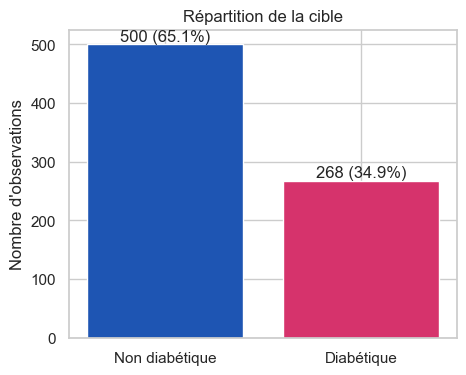

In [33]:
effectifs = df[TARGET].value_counts().sort_index()
pourcents = (df[TARGET].value_counts(normalize=True).sort_index() * 100).round(1)
etiquettes = [NOMS_CLASSES[i] for i in effectifs.index]
plt.figure(figsize=(5, 4))
plt.bar(etiquettes, effectifs.values, color=["#1E55B3", "#D6336C"])
for i, (n, p) in enumerate(zip(effectifs.values, pourcents.values)):
    plt.text(i, n, f"{n} ({p}%)", ha="center", va="bottom")
plt.title("Répartition de la cible"); plt.ylabel("Nombre d'observations"); plt.show()

INTERPRETATION 1 : 
- 500 non diabétiques (65,1 %) contre 268 diabétiques (34,9 %). Le déséquilibre est modéré : un modèle qui répondrait toujours « non » aurait 65 % d’accuracy. C’est pourquoi l’accuracy seule est trompeuse et pourquoi on utilise class_weight="balanced", le rappel et le ROC-AUC.

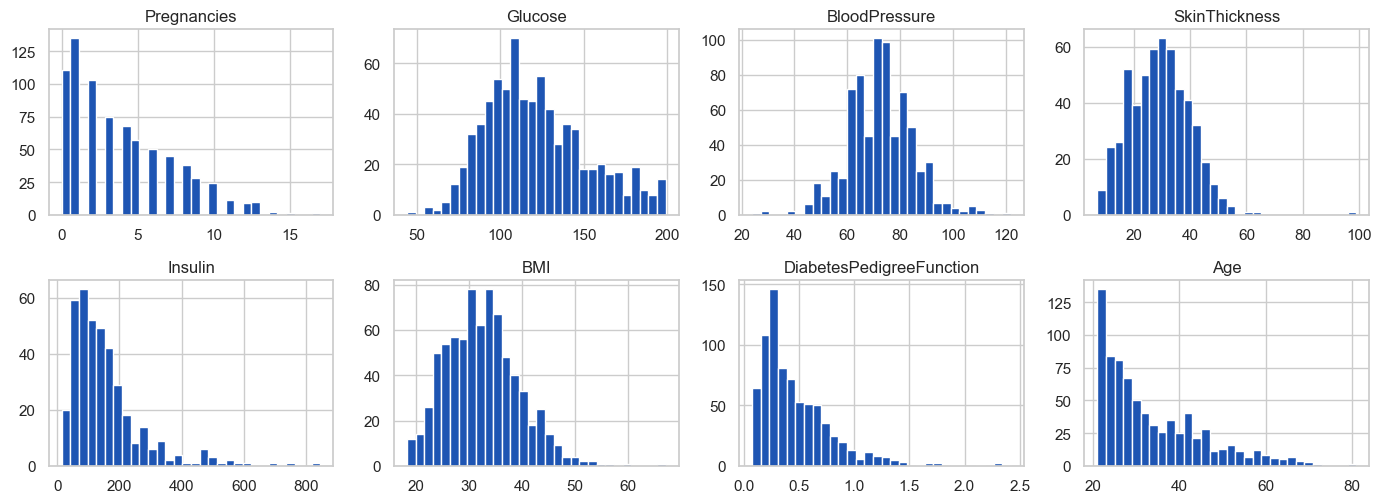

In [34]:
a_tracer = num_cols[:12]
if len(num_cols) > 12:
    print(f"(On n'affiche que les 12 premières variables numériques sur {len(num_cols)}.)")
df[a_tracer].hist(bins=30, figsize=(14, 3 + 2.2 * ((len(a_tracer) - 1) // 4)), color="#1E55B3", layout=(-1, 4))
plt.tight_layout(); plt.show()

INTERPRETATION 2: 
- Pregnancies : asymétrique à droite, avec un pic à 0-1 et une longue queue jusqu’à 17. La plupart ont peu de grossesses.
- Glucose : en cloche, centrée autour de 117 avec une légère queue à droite. Une partie des valeurs dépasse 140, ce qui est préoccupant.
- BloodPressure : en cloche presque symétrique, centrée autour de 72. C’est la distribution la plus « normale ».
- SkinThickness : pic autour de 29, un peu asymétrique à droite, avec une valeur extrême à 99 (probablement une erreur de saisie). Environ 30 % des valeurs manquent.
- Insulin : très asymétrique à droite (la plupart sous 200, des valeurs jusqu’à 846). Près de la moitié des valeurs manquent, donc la médiane imputée est peu fiable.
- BMI : en cloche centrée autour de 32, avec quelques valeurs extrêmes jusqu’à 67. Environ 61 % des patientes ont un IMC d’au moins 30, donc l’obésité est très répandue dans l’échantillon.
- DiabetesPedigreeFunction : très asymétrique à droite, la majorité sous 0,6 avec une queue jusqu’à 2,4.
- Age : asymétrique à droite, minimum 21 ans, environ 75 % ont 40 ans ou moins. L’échantillon est donc jeune.

In [35]:
a_tracer = cat_cols[:6]
if a_tracer:
    n = len(a_tracer)
    fig, axes = plt.subplots((n + 1) // 2, 2, figsize=(13, 3.6 * ((n + 1) // 2)))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, a_tracer):
        ordre = df[col].value_counts().head(10).index
        sns.countplot(y=df[col], order=ordre, ax=ax, color="#1E55B3")
        ax.set_title(col)
    for ax in axes[len(a_tracer):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()
else:
    print("Pas de variable catégorielle dans ce jeu de données.")

Pas de variable catégorielle dans ce jeu de données.


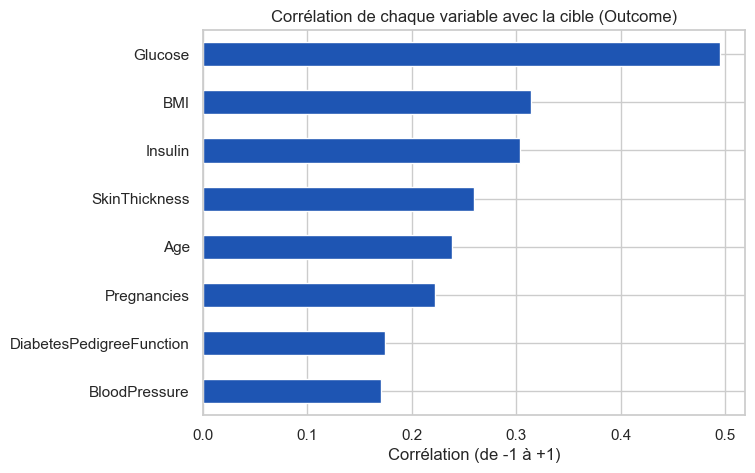

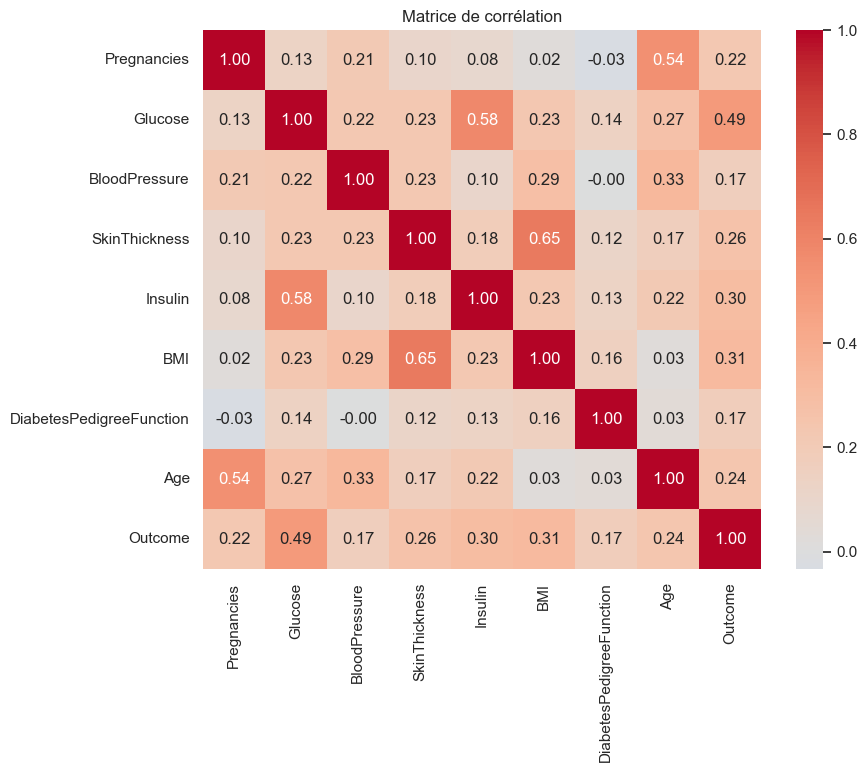

In [36]:
corr_cible = df[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values(key=abs, ascending=False)
plt.figure(figsize=(7, 5))
corr_cible.head(15)[::-1].plot(kind="barh", color="#1E55B3")
plt.title(f"Corrélation de chaque variable avec la cible ({TARGET})")
plt.xlabel("Corrélation (de -1 à +1)"); plt.show()

if len(num_cols) <= 12:
    plt.figure(figsize=(9, 7))
    sns.heatmap(df[num_cols + [TARGET]].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Matrice de corrélation"); plt.show()

INTERPRETATION : 
- Glucose–Insulin : 0,58, la corrélation la plus forte avec une variable utile. C’est logique, car l’insuline régule la glycémie.
- BMI–SkinThickness : 0,65, la plus forte de toutes. Les deux mesurent la masse grasse, donc l’information est redondante.
- Age–Pregnancies : 0,54. Plus on est âgée, plus on a eu de grossesses.
- Les autres corrélations sont faibles ou modérées, donc il y a peu de redondance au-delà de ces trois paires.
- Ces redondances ne posent pas de problème pour la forêt ou le boosting. Elles peuvent légèrement perturber l’interprétation des coefficients de la régression logistique.

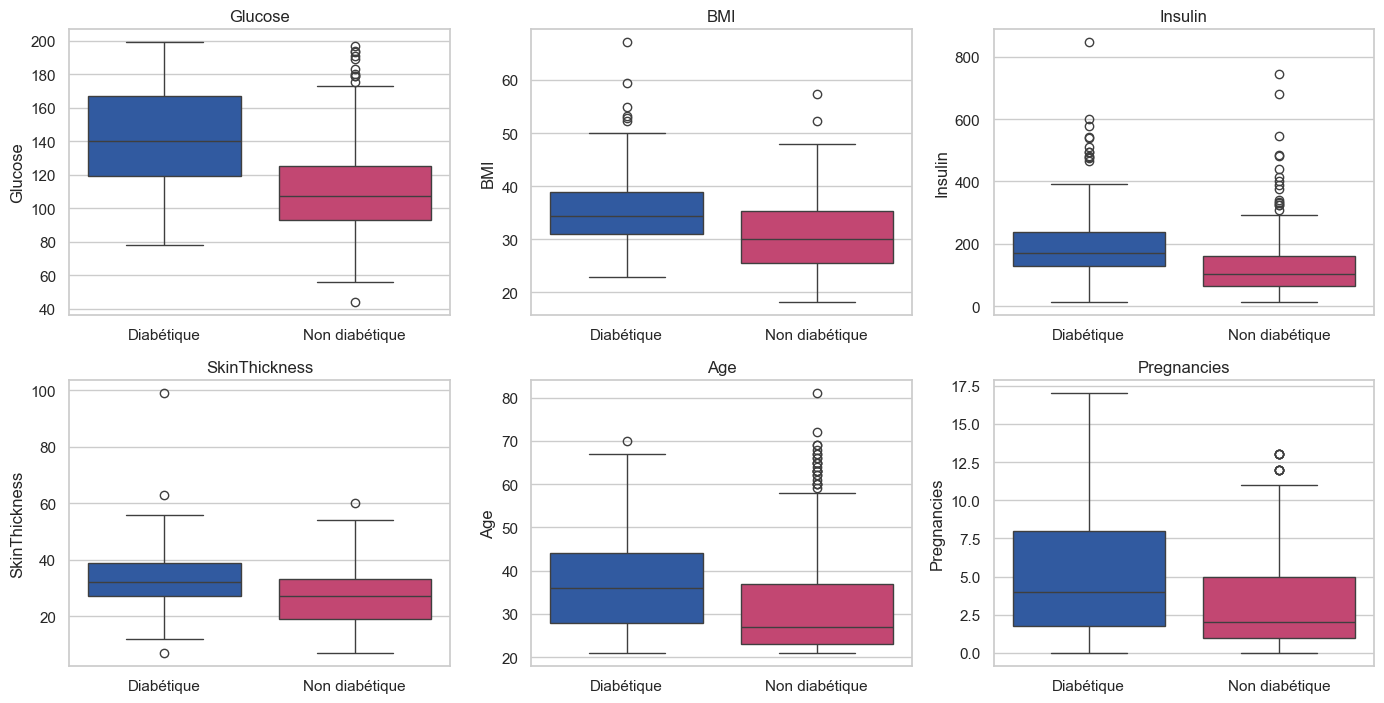

In [37]:
# Variables numériques : comparer les deux groupes
top_num = corr_cible.head(6).index.tolist()
if top_num:
    n = len(top_num)
    fig, axes = plt.subplots((n + 2) // 3, 3, figsize=(14, 3.6 * ((n + 2) // 3)))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, top_num):
        sns.boxplot(x=df[TARGET].map(lambda i: NOMS_CLASSES[i]), y=df[col], ax=ax, palette=["#1E55B3", "#D6336C"])
        ax.set_xlabel(""); ax.set_title(col)
    for ax in axes[len(top_num):]:
        ax.axis("off")
    plt.tight_layout(); plt.show()

# Variables catégorielles : part de "positifs" dans chaque catégorie
for col in cat_cols[:4]:
    taux = df.groupby(col)[TARGET].mean().sort_values(ascending=False) * 100
    plt.figure(figsize=(8, 3))
    taux.plot(kind="bar", color="#D6336C")
    plt.axhline(df[TARGET].mean() * 100, color="gray", linestyle="--", label="Moyenne générale")
    plt.ylabel(f"% de « diabète »"); plt.title(f"diabète selon {col}"); plt.legend()
    plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

INTERPRETATION : 
- Glucose : le meilleur séparateur. Médiane de 140 contre 107, et les boîtes se chevauchent à peine (Q1 des diabétiques à 119, Q3 des non diabétiques à 125).
- BMI : médiane de 34,3 contre 30,1, avec un chevauchement important. Le groupe diabétique est un peu plus corpulent mais la séparation reste partielle.
- Insulin : médiane de 169 contre 102, avec de nombreuses valeurs extrêmes élevées. La différence existe, mais les valeurs imputées la brouillent.
- SkinThickness : médiane de 32 contre 27, avec un très fort chevauchement. Cette variable sépare peu.
- Age : médiane de 36 contre 27. Les diabétiques sont plus âgées, mais l’écart est modeste.
- Pregnancies : médiane de 4 contre 2, avec un chevauchement important. Cet effet est en partie dû à l’âge (corrélation de 0,54 entre les deux).
- Les points isolés sont des valeurs extrêmes. Ils ne sont pas supprimés ici, car ce sont des valeurs possibles.

🤔 **Questions pour l'équipe**
- Quelles variables séparent le mieux les personnes diabétiques des autres ?
- Que pensez-vous du nombre de valeurs manquantes sur l'insuline et l'épaisseur de peau ? Faut-il garder ces colonnes ?
- La glycémie est-elle une « cause » du diabète ou plutôt un « symptôme » ? Cela change-t-il l'usage du modèle ?

REPONSES AUX QUESTIONS:  
- La glycémie est de loin la meilleure : corrélation de 0,49, médiane de 140 chez les diabétiques contre 107 chez les autres. Viennent ensuite l’IMC (0,31), l’insuline (0,30) et l’âge (0,24). Les plus faibles sont la tension (0,17) et les antécédents familiaux (0,17).

- On les garde dans le pipeline, car l’imputation par la médiane permet de les utiliser. Il faut cependant savoir qu’elles apportent peu. Leur importance par permutation est proche de 0 (0,002 pour l’insuline, 0,000 pour la peau), et elles sont redondantes avec d’autres variables : la peau avec l’IMC (corrélation 0,65) et l’insuline avec la glycémie (0,58). Imputer près de la moitié d’une colonne avec une valeur unique revient aussi à inventer de l’information. La bonne démarche est de tester le modèle avec et sans ces deux colonnes, puis de garder la version la plus simple si le score ne baisse pas.

- C’est un symptôme, ou plutôt un marqueur : le diabète se définit justement par une glycémie élevée. Le modèle sert donc à repérer un diabète déjà présent mais non diagnostiqué. Il ne prédit pas qui deviendra diabétique plus tard. Pour de la prévention, il faudrait retirer la glycémie et s’appuyer sur l’âge, l’IMC et les antécédents. Le modèle serait alors nettement moins performant.


## 5. Préparer les données pour les modèles
- **Découpage entraînement / test** : on cache 20 % des données. Le modèle apprend sur 80 %, puis on le juge sur les 20 % qu'il n'a jamais vus, comme ce serait le cas en vrai.
- **Valeurs manquantes** : remplacées par la médiane (nombres) ou la valeur la plus fréquente (catégories).
- **Mise à l'échelle** : les nombres sont ramenés à une même échelle.
- **Encodage** : les catégories sont transformées en colonnes 0/1 (*one-hot*), car les modèles ne comprennent que des nombres.

⚠️ **Fuite de données** : toutes ces transformations doivent être « apprises » sur l'entraînement **uniquement**. Si on les calculait sur toutes les données, le test influencerait l'entraînement et le score serait trop beau pour être vrai. Le `Pipeline` ci-dessous règle ce problème automatiquement.

In [38]:
FEATURES = [c for c in df.columns if c != TARGET]
# ✏️ À TOI (4/5) : sépare ce qu'on connaît (X) de ce qu'on prédit (y), puis découpe 80 % / 20 %
X = df[FEATURES]  # les colonnes listées dans FEATURES
y = df[TARGET]   # la colonne TARGET
# Indice : train_test_split(X, y, test_size=..., random_state=RANDOM_STATE)
# Pour une classification, ajoute stratify=y : les deux groupes gardent les mêmes proportions.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print("Entraînement :", X_train.shape[0], "lignes | Test :", X_test.shape[0], "lignes")


def construire_preprocess(donnees):
    """Prépare les variables : numériques (valeurs manquantes + mise à l'échelle) et catégorielles (encodage 0/1)."""
    num = donnees.select_dtypes(include="number").columns.tolist()
    cat = donnees.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                          ("scaler", StandardScaler())]), num),
        ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat),
    ])

Entraînement : 614 lignes | Test : 154 lignes


<details><summary>💡 Je bloque : voir la solution (4/5)</summary>

```python
X = df[FEATURES]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
```
</details>

## 6. Quel modèle pour quel problème ?

Notre problème est une **classification** : on veut prédire **une catégorie** (diabétique ou non). Quand la réponse est un nombre (un prix, une note…), on parle de **régression** : c'est l'objet d'autres notebooks.

Il n'existe pas de « meilleur modèle » universel : on en essaie plusieurs et on les compare sur des données qu'ils n'ont **jamais vues**.

| Modèle | Principe en une phrase | À utiliser quand… | Limites |
|---|---|---|---|
| **Régression logistique** | Calcule une probabilité à partir d'une somme pondérée des variables (malgré son nom, c'est bien de la classification). | Point de départ, relation assez simple, on veut des explications. | Ne capte pas les relations compliquées. |
| **Forêt aléatoire** (*Random Forest*) | Fait voter de nombreux arbres de décision (des suites de questions oui/non), chacun entraîné sur un échantillon différent. | Relations non linéaires, beaucoup de variables mélangées. | Moins facile à expliquer. |
| **Gradient Boosting** | Construit des arbres l'un après l'autre : chaque arbre corrige les erreurs des précédents. | Souvent le plus précis sur les tableaux de données. | Plus sensible aux réglages, risque de sur-apprentissage. |

**Comment juger un modèle de classification ?** On regarde la **matrice de confusion** (vrais positifs, faux positifs, vrais négatifs, faux négatifs), puis :
- **Accuracy** : part de bonnes réponses. ⚠️ *Trompeuse quand les classes sont déséquilibrées* : un modèle qui répond toujours « non » a une bonne accuracy s'il y a beaucoup de « non ».
- **Précision** : quand le modèle annonce « positif », a-t-il raison ?
- **Rappel** (*recall*) : parmi les vrais positifs, combien le modèle en retrouve-t-il ?
- **F1** : un compromis entre précision et rappel.
- **ROC-AUC** : capacité à classer les positifs au-dessus des négatifs (0,5 = hasard, 1 = parfait).
- **Seuil de décision** : le modèle donne une probabilité ; par défaut on dit « positif » à partir de 0,5, mais on peut choisir un autre seuil selon le coût des erreurs.

⚖️ **Classes déséquilibrées.** Ici, la classe « diabète » est minoritaire. Pour que le modèle ne l'ignore pas, la régression logistique et la forêt aléatoire utilisent `class_weight="balanced"` (la classe rare pèse plus lourd). Le Gradient Boosting de scikit-learn n'a pas cette option dans ce notebook, ce qui rend la comparaison intéressante.

On ajoute un **modèle de référence** qui répond toujours la classe la plus fréquente : si un vrai modèle ne fait pas mieux, il ne sert à rien.

📚 *Pour aller plus loin (documentation scikit-learn, en anglais) :* [régression logistique](https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression) · [forêts et boosting](https://scikit-learn.org/stable/modules/ensemble.html) · [évaluer un modèle](https://scikit-learn.org/stable/modules/model_evaluation.html)

## 7. Entraîner et comparer trois modèles
Pour chaque modèle : une **validation croisée** (on entraîne 5 fois sur des morceaux différents pour vérifier que le résultat est stable), puis une évaluation finale sur le jeu de test.

In [39]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
POIDS = "balanced" if EQUILIBRER else None

modeles = {
    "Référence (toujours la classe majoritaire)": DummyClassifier(strategy="most_frequent"),
    "Régression logistique": LogisticRegression(max_iter=2000, class_weight=POIDS),
    "Forêt aléatoire": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, class_weight=POIDS, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
}


def faire_modele(estimateur, X_ref=X_train):
    """Assemble préparation des données + modèle."""
    return Pipeline([("prep", construire_preprocess(X_ref)), ("model", estimateur)])


lignes, entraines = [], {}
for nom, estimateur in modeles.items():
    modele = faire_modele(estimateur)
    cv_auc = cross_val_score(modele, X_train, y_train, cv=cv, scoring="roc_auc").mean()
    modele.fit(X_train, y_train)
    pred = modele.predict(X_test)
    proba = modele.predict_proba(X_test)[:, 1]
    lignes.append({
        "Modèle": nom,
        "ROC-AUC validation croisée": cv_auc,
        "Accuracy test": accuracy_score(y_test, pred),
        "Précision test": precision_score(y_test, pred, zero_division=0),
        "Rappel test": recall_score(y_test, pred, zero_division=0),
        "F1 test": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC test": roc_auc_score(y_test, proba),
    })
    entraines[nom] = modele

resultats = pd.DataFrame(lignes).set_index("Modèle")
resultats.style.format("{:.3f}")

,ROC-AUC validation croisée,Accuracy test,Précision test,Rappel test,F1 test,ROC-AUC test
Modèle,,,,,,
Référence (toujours la classe majoritaire),0.500,0.649,0.000,0.000,0.000,0.500
Régression logistique,0.844,0.734,0.603,0.704,0.650,0.813
Forêt aléatoire,0.832,0.760,0.667,0.630,0.648,0.822
Gradient Boosting,0.821,0.760,0.689,0.574,0.626,0.831


## 8. Comparer les résultats
🤔 *Quel modèle est le meilleur ? L'écart avec la référence est-il grand ? Y a-t-il du sur-apprentissage ?*

Meilleur modèle (d'après le ROC-AUC en validation croisée) : Régression logistique


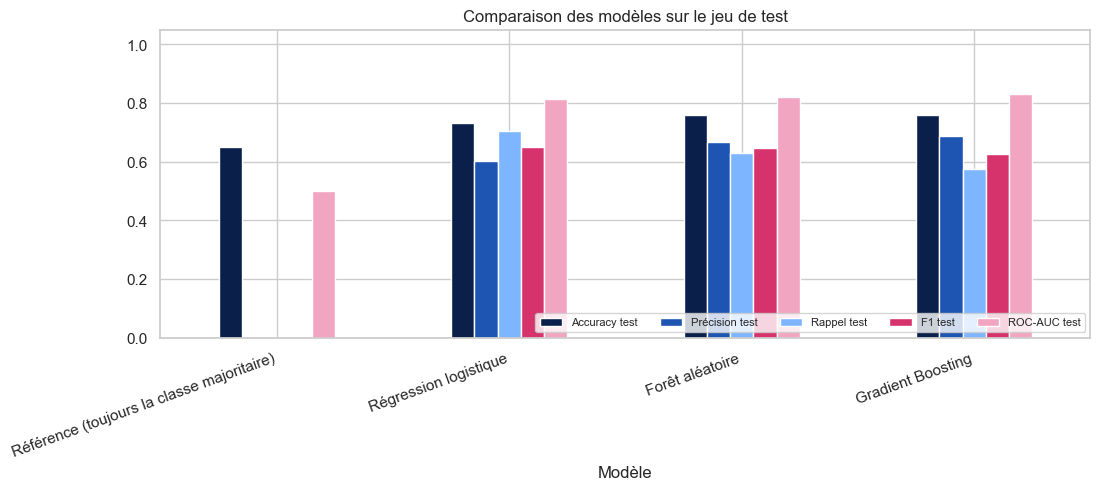

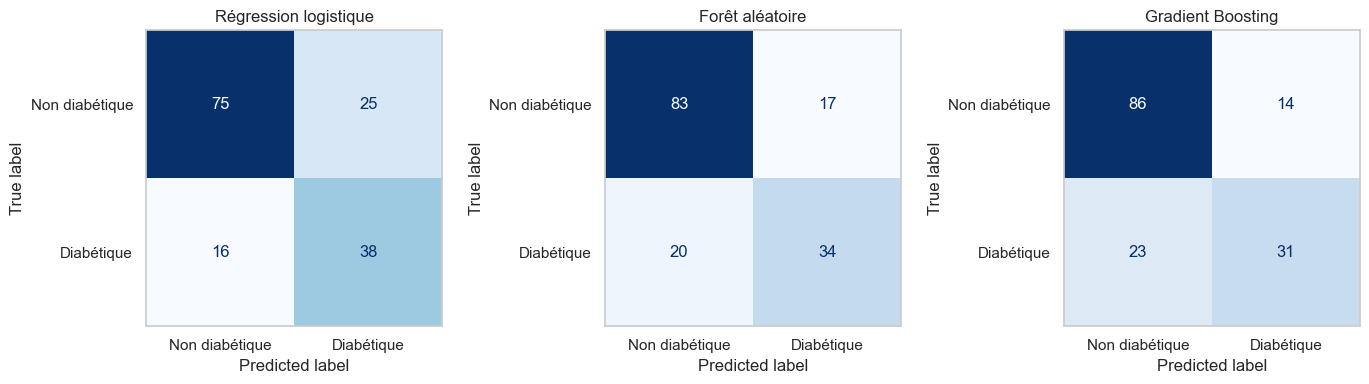

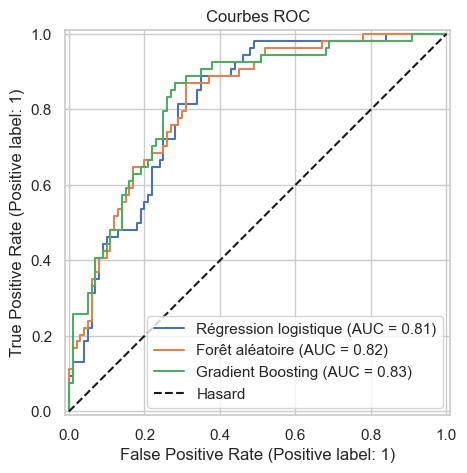

Rapport détaillé du meilleur modèle (Régression logistique) :
                precision    recall  f1-score   support

Non diabétique       0.82      0.75      0.79       100
    Diabétique       0.60      0.70      0.65        54

      accuracy                           0.73       154
     macro avg       0.71      0.73      0.72       154
  weighted avg       0.75      0.73      0.74       154



In [40]:
vrais_modeles = resultats.drop(index="Référence (toujours la classe majoritaire)")
meilleur_nom = vrais_modeles["ROC-AUC validation croisée"].idxmax()
meilleur_modele = entraines[meilleur_nom]
print("Meilleur modèle (d'après le ROC-AUC en validation croisée) :", meilleur_nom)

resultats[["Accuracy test", "Précision test", "Rappel test", "F1 test", "ROC-AUC test"]].plot(
    kind="bar", figsize=(12, 4), color=["#0B1F4B", "#1E55B3", "#7DB6FF", "#D6336C", "#F2A5C0"])
plt.title("Comparaison des modèles sur le jeu de test"); plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right"); plt.legend(loc="lower right", ncol=5, fontsize=8); plt.show()

# Matrices de confusion
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, nom in zip(axes, ["Régression logistique", "Forêt aléatoire", "Gradient Boosting"]):
    ConfusionMatrixDisplay.from_estimator(entraines[nom], X_test, y_test, display_labels=NOMS_CLASSES,
                                          ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(nom); ax.grid(False)
plt.tight_layout(); plt.show()

# Courbes ROC
plt.figure(figsize=(6, 5))
ax = plt.gca()
for nom in ["Régression logistique", "Forêt aléatoire", "Gradient Boosting"]:
    RocCurveDisplay.from_estimator(entraines[nom], X_test, y_test, ax=ax, name=nom)
plt.plot([0, 1], [0, 1], "k--", label="Hasard"); plt.title("Courbes ROC"); plt.legend(); plt.show()

print(f"Rapport détaillé du meilleur modèle ({meilleur_nom}) :")
print(classification_report(y_test, meilleur_modele.predict(X_test), target_names=NOMS_CLASSES))

### Le seuil de décision
Par défaut, le modèle dit « diabète » si la probabilité dépasse 0,5. En baissant le seuil, on détecte plus de cas positifs (le **rappel** monte) mais on se trompe plus souvent quand on les annonce (la **précision** baisse).

🩺 **Quelle erreur est la plus grave ici ?** Un **faux négatif** (personne diabétique non détectée) retarde la prise en charge. Un **faux positif** (personne saine alertée) mène à un examen de confirmation, ce qui est moins grave. On souhaite donc un **bon rappel** sur la classe « diabète ».

In [41]:
proba = meilleur_modele.predict_proba(X_test)[:, 1]
lignes = []
for seuil in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    pred = (proba >= seuil).astype(int)
    lignes.append({"Seuil": seuil,
                   "Annoncés « diabète »": int(pred.sum()),
                   "Précision": precision_score(y_test, pred, zero_division=0),
                   "Rappel": recall_score(y_test, pred, zero_division=0),
                   "F1": f1_score(y_test, pred, zero_division=0)})
pd.DataFrame(lignes).set_index("Seuil").style.format({"Précision": "{:.2f}", "Rappel": "{:.2f}", "F1": "{:.2f}"})

,Annoncés « diabète »,Précision,Rappel,F1
Seuil,,,,
0.200000,103,0.51,0.98,0.68
0.300000,88,0.55,0.89,0.68
0.400000,79,0.57,0.83,0.68
0.500000,63,0.60,0.70,0.65
0.600000,52,0.60,0.57,0.58
0.700000,42,0.62,0.48,0.54


## 9. Pour aller plus loin
### Quelles variables comptent le plus ?
L'**importance par permutation** mesure de combien le score baisse quand on mélange une variable au hasard : plus la baisse est grande, plus le modèle comptait sur elle.

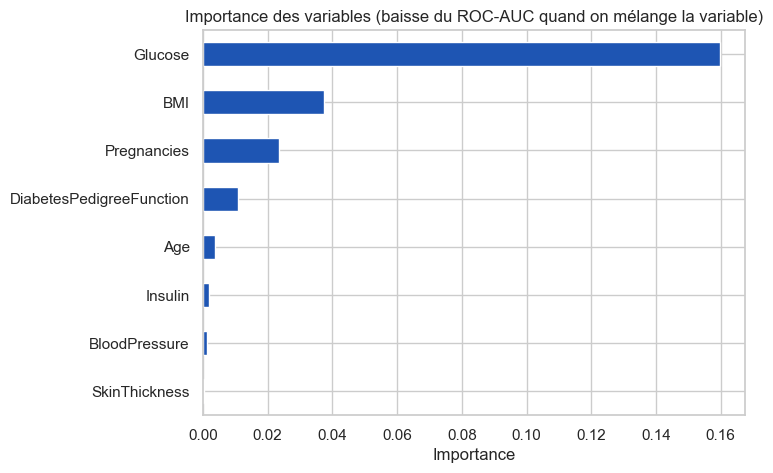

In [42]:
imp = permutation_importance(meilleur_modele, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1)
importances = pd.Series(imp.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(7, 5))
importances.head(12)[::-1].plot(kind="barh", color="#1E55B3")
plt.title("Importance des variables (baisse du ROC-AUC quand on mélange la variable)")
plt.xlabel("Importance"); plt.show()

### Régler un modèle (optionnel)
Chaque modèle a des **hyperparamètres** (ses « boutons de réglage »). On peut chercher automatiquement les meilleurs avec `GridSearchCV`.

In [43]:
# ⏱️ Optionnel : ~1-2 minutes. On teste quelques réglages de la forêt aléatoire.
grille = {
    "model__max_depth": [None, 8, 16],
    "model__min_samples_leaf": [1, 3, 6],
}
recherche = GridSearchCV(faire_modele(RandomForestClassifier(n_estimators=200, class_weight=POIDS, random_state=RANDOM_STATE, n_jobs=-1)),
                         grille, cv=3, scoring="roc_auc")
recherche.fit(X_train, y_train)
print("Meilleurs réglages :", {k.split("__")[-1]: v for k, v in recherche.best_params_.items()})
proba_rf = recherche.predict_proba(X_test)[:, 1]
print(f"ROC-AUC test avant réglage : {resultats.loc['Forêt aléatoire', 'ROC-AUC test']:.3f} → après réglage : {roc_auc_score(y_test, proba_rf):.3f}")

Meilleurs réglages : {'max_depth': 8, 'min_samples_leaf': 6}
ROC-AUC test avant réglage : 0.822 → après réglage : 0.819


## 10. Conclusion et préparation du Demo Day

### Ce que nous avons appris
- Un bon nettoyage (les zéros impossibles) est aussi important que le choix du modèle.
- Les performances sont **bonnes sans être parfaites** : les mesures disponibles ne suffisent pas à tout prédire.
- Le **seuil de décision** permet d'arbitrer entre « ne rater personne » et « ne pas alerter pour rien ».

### 🤔 Pour préparer le Demo Day
1. Dans quel contexte ce modèle serait-il utile ? (campagne de dépistage, pharmacie, application de santé…)
2. Quel seuil choisiriez-vous, et pourquoi ?
3. Les données concernent un groupe précis de femmes : peut-on les généraliser à toute la population sénégalaise ?

In [44]:
import joblib

# ✏️ À TOI (5/5) : sauvegarde le modèle, puis recharge-le
# Indice : joblib.dump(objet_à_sauvegarder, "nom_du_fichier.joblib") et joblib.load("nom_du_fichier.joblib")
joblib.dump(meilleur_modele, "modele_diabete.joblib")
modele_recharge = joblib.load("modele_diabete.joblib")
print("Modèle sauvegardé dans modele_diabete.joblib : il pourra être rechargé dans l'application (jeudi).")

# Exemple d'utilisation : on prend une ligne du jeu de test et on modifie quelques valeurs
exemple = X_test.iloc[[0]].copy()
exemple["Glucose"] = 150
exemple["BMI"] = 35
exemple["Age"] = 45
print("Cas testé :")
display(exemple.T)
p = modele_recharge.predict_proba(exemple)[0, 1]
print(f"Probabilité de « diabète » : {p:.0%}")

Modèle sauvegardé dans modele_diabete.joblib : il pourra être rechargé dans l'application (jeudi).
Cas testé :


,44
Pregnancies,7.000
Glucose,150.000
BloodPressure,64.000
SkinThickness,NaN
Insulin,NaN
BMI,35.000
DiabetesPedigreeFunction,0.294
Age,45.000


Probabilité de « diabète » : 82%


<details><summary>💡 Je bloque : voir la solution (5/5)</summary>

```python
joblib.dump(meilleur_modele, "modele_diabete.joblib")
modele_recharge = joblib.load("modele_diabete.joblib")
```
</details>

### Pour l'application de jeudi
Le fichier `.joblib` contient tout le pipeline (préparation + modèle). Dans l'application, il suffira de :
```python
modele = joblib.load("nom_du_fichier.joblib")
modele.predict(nouvelles_donnees)   # un DataFrame avec les mêmes colonnes que X
```
---
*Notebook réalisé pour le UMEF AI Bootcamp (GalsenAI Ambassador Program). Les explications sont volontairement simples : n'hésite pas à poser des questions aux mentors !*